## Homework 2

> [!NOTE]
> This homework uses the pinned 2026 car fuel-efficiency release in the course
> repository. The plan and report are available in `cohorts/2026/data/`.

Énoncé : https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/02-regression/homework.md


### Dataset

For this homework, we'll use the 2026 Car Fuel Efficiency dataset. Download it from <a href='https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'>here</a>.

You can do it with wget:

```bash
wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
```

The goal of this homework is to create a regression model for predicting the car fuel efficiency (column `'fuel_efficiency_mpg'`).


In [19]:
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
)

print(df.head())
print(df.shape)

   model_year  origin fuel_type         drivetrain  num_doors  \
0        2006  Europe  Gasoline  Front-wheel drive          4   
1        2008  Europe    Diesel  Front-wheel drive          4   
2        1996    Asia  Gasoline  Front-wheel drive          5   
3        1989  Europe  Gasoline  Front-wheel drive          4   
4        1994     USA    Diesel  Front-wheel drive          3   

   engine_displacement  num_cylinders  horsepower  vehicle_weight  \
0                 2180              6       243.0            3870   
1                 2390              6       272.0            4210   
2                 2320              6       267.0            4240   
3                 2130              6       258.0            4490   
4                 2580              7       304.0            4510   

   acceleration  fuel_efficiency_mpg  
0           NaN                 31.9  
1           NaN                 31.3  
2          17.3                 27.5  
3          18.7                 28.5  

### Preparing the dataset

Use only the following columns:

- `'engine_displacement'`,
- `'horsepower'`,
- `'vehicle_weight'`,
- `'model_year'`,
- `'fuel_efficiency_mpg'`


In [20]:
df = df[
    [
        "engine_displacement",
        "horsepower",
        "vehicle_weight",
        "model_year",
        "fuel_efficiency_mpg",
    ]
]
df = df.copy()
print(df.head())
print(df.shape)

   engine_displacement  horsepower  vehicle_weight  model_year  \
0                 2180       243.0            3870        2006   
1                 2390       272.0            4210        2008   
2                 2320       267.0            4240        1996   
3                 2130       258.0            4490        1989   
4                 2580       304.0            4510        1994   

   fuel_efficiency_mpg  
0                 31.9  
1                 31.3  
2                 27.5  
3                 28.5  
4                 31.0  
(10000, 5)


### EDA

- Look at the `fuel_efficiency_mpg` variable. Does it have a long tail?


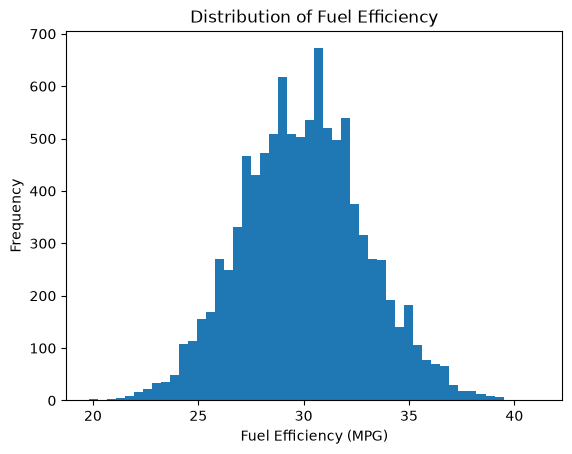

In [21]:
from matplotlib import pyplot as plt


plt.hist(df["fuel_efficiency_mpg"], bins=50)
plt.xlabel("Fuel Efficiency (MPG)")
plt.ylabel("Frequency")
plt.title("Distribution of Fuel Efficiency")
plt.show()


### Question 1

There's one column with missing values. What is it?

- `'engine_displacement'`
- `'horsepower'`
- `'vehicle_weight'`
- `'model_year'`


In [22]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

### Question 2

What's the median (50% percentile) for variable `'horsepower'`?

- 204
- 254
- 304
- 354


In [23]:
df["horsepower"].median()

np.float64(254.0)

### Prepare and split the dataset

Shuffle the filtered dataset and create the split exactly as in the lecture:

```python
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]
```

For Q5, repeat the same block with each listed seed. For Q6, use seed `9`.


In [24]:
import numpy as np

n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train : n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val :]]

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values

del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

print(len(df_train), len(df_val), len(df_test))
print(df_train.columns)

6000 2000 2000
Index(['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year'],
      dtype='str')


### Question 3

- We need to deal with missing values for the column from Q1.
- We have two options: fill it with 0 or with the mean of this variable.
- Try both options. For each, train a linear regression model without regularization using the code from the lessons.
- For computing the mean, use the training only!
- Use the validation dataset to evaluate the models and compare the RMSE of each option.
- Round the RMSE scores to 3 decimal digits using `round(score, 3)`. This
  keeps the imputation difference visible in this release.
- Which option gives better RMSE?

Options:

- With 0
- With mean
- Both are equally good


In [25]:
def prepare_X(df, valeur):
    df = df.copy()
    df = df.fillna(valeur)
    return df.values


X = prepare_X(df_train, 0)
print(X.shape)


(6000, 4)


In [26]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    return w[0], w[1:]


w0, w = train_linear_regression(X, y_train)
print(w0, w)

-153.8849618823138 [-1.51505520e-03 -4.74024794e-06 -3.95418397e-03  1.02146785e-01]


In [27]:
def rmse(y, y_pred):
    error = y - y_pred
    return np.sqrt(np.mean(error**2))


rmse(np.array([1, 2, 3]), np.array([1, 2, 5]))

np.float64(1.1547005383792515)

In [28]:
X_train = prepare_X(df_train, 0)
w0, w = train_linear_regression(X_train, y_train)
X_val = prepare_X(df_val, 0)
y_pred = w0 + X_val.dot(w)
round(rmse(y_val, y_pred), 3)

np.float64(2.205)

In [29]:
moyenne = df_train["horsepower"].mean()
X_train = prepare_X(df_train, moyenne)
w0, w = train_linear_regression(X_train, y_train)
X_val = prepare_X(df_val, moyenne)
y_pred = w0 + X_val.dot(w)
round(rmse(y_val, y_pred), 3)

np.float64(2.202)

### Question 4

- Now let's train a regularized linear regression.
- For this question, fill the NAs with 0.
- Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
- Use RMSE to evaluate the model on the validation dataset.
- Round the RMSE scores to 4 decimal digits. This keeps the small but real
  regularization differences visible instead of turning several choices into a tie.
- Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0
- 0.01
- 0.1
- 1
- 5
- 10
- 100


In [30]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


X_train = prepare_X(df_train, 0)
w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

X_val = prepare_X(df_val, 0)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(2.2058276166720066)

In [31]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X(df_train, 0)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val, 0)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, round(score, 4))

0 -153.8849618823138 2.2053
0.01 -148.3092124404723 2.2058
0.1 -111.83871039306318 2.2241
1 -32.331865964971264 2.3492
5 -7.7728522099734025 2.4094
10 -3.9871164160193766 2.4195
100 -0.40821964884790385 2.4292


**Réponse Q4 : 0**

Le meilleur RMSE sur la validation est 2.2053, obtenu avec `r = 0`. Plus `r` augmente, plus le RMSE monte : ici, la régularisation n'améliore pas le modèle.


### Question 5

- We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
- Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
- For each seed, do the train/validation/test split with 60%/20%/20% distribution.
- Fill the missing values with 0 and train a model without regularization.
- For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
- What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
- Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?

- 0.006
- 0.016
- 0.029
- 0.036

> Note: Standard deviation shows how different the values are.
> If it's low, then all values are approximately the same.
> If it's high, the values are different.
> If standard deviation of scores is low, then our model is _stable_.


In [33]:
def decouper(df, seed=42):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train : n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val :]]

    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)

    y_train = df_train["fuel_efficiency_mpg"].values
    y_val = df_val["fuel_efficiency_mpg"].values
    y_test = df_test["fuel_efficiency_mpg"].values

    del df_train["fuel_efficiency_mpg"]
    del df_val["fuel_efficiency_mpg"]
    del df_test["fuel_efficiency_mpg"]

    return df_train, df_val, df_test, y_train, y_val, y_test


scores = []
for seed in range(10):
    df_train, df_val, df_test, y_train, y_val, y_test = decouper(df, seed=seed)

    X_train = prepare_X(df_train, 0)
    w0, w = train_linear_regression(X_train, y_train)

    X_val = prepare_X(df_val, 0)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    scores.append(score)
    print(seed, round(score, 4))

print(round(np.std(scores), 3))

0 2.2392
1 2.2021
2 2.1634
3 2.2044
4 2.2019
5 2.2458
6 2.2697
7 2.1908
8 2.2166
9 2.207
0.029


**Réponse Q5 : 0.029**

L'écart-type des 10 RMSE (graines de 0 à 9) est 0.029. C'est très petit par rapport au RMSE moyen d'environ 2,2 : le modèle donne presque le même résultat quel que soit le découpage, il est stable.


### Question 6

- Split the dataset like previously, use seed 9.
- Combine train and validation datasets.
- Fill the missing values with 0 and train a model with `r=0.001`.
- What's the RMSE on the test dataset?

Options:

- 0.236
- 2.236
- 22.10
- 221.0


In [34]:
X_test = prepare_X(df_test, 0)
y_pred = w0 + X_test.dot(w)
rmse(y_test, y_pred)

np.float64(2.236359398578206)

**Réponse Q6 : 2.236**

Avec la graine 9, le modèle entraîné sur l'entraînement plus la validation (8 000 voitures), avec `r = 0.001`, a un RMSE de 2.236 sur le test. C'est proche des RMSE de validation (environ 2,2) : le modèle se comporte aussi bien sur des voitures qu'il n'a jamais vues.
